# Hot Coffee

When you wrap your fingers around a ceramic mug filled with hot coffee, the mug will warm your hands, but the coffee will cool down quickly. In contrast, an insulated metal mug with an air layer is designed to prevent heat transfer, so it won't feel warm to the touch even if it contains scalding liquid. But will the coffee in this mug stay warm for a significantly longer period of time?

Let's also consider lids. How crucial is it to use a lid on an insulated cup to maintain the drink's temperature?

In the file `hot-coffee.csv`, we have data recording the temperature (in Fahrenheit) of initially hot coffee every 5 minutes in three types of cups:

- Insulated with a lid
- Insulated without a lid
- Ceramic without a lid

In [1]:
# FOR GOOGLE COLAB ONLY.
# Uncomment and run the code below. A dialog will appear to upload files.
# Upload 'hot-coffee.csv'.

# from google.colab import files
# uploaded = files.upload()

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('hot-coffee.csv')
df

,time,insulated with lid,insulated,ceramic
0,5,146.6,135.5,128.8
1,10,141.0,118.9,113.9
2,15,136.7,107.9,102.5
3,20,132.5,100.5,95.9
4,25,129.0,94.6,90.5
5,30,125.6,90.8,86.3
6,35,123.4,87.6,83.6
7,40,121.6,85.4,81.6
8,45,118.5,82.9,79.8
9,50,117.6,81.3,78.2


### Project Ideas:

- Create a line plot showing the temperature of the coffee in all three scenarios versus time. 

- Follow the Pro Tips for creating line plots.

- For comparison, consider adding a line representing the ambient air temperature, which was 67 degrees Fahrenheit.

Below is a helper function to label lines for your convenience.

In [3]:
def add_end_labels(df, x, column_names, alpha=1, fontweight='normal'):
    for column_name in column_names:
        y = df[column_name].iloc[-1]
        label = f'  {column_name}'
        plt.text(x, y, label, va="center", alpha=alpha, fontweight=fontweight)

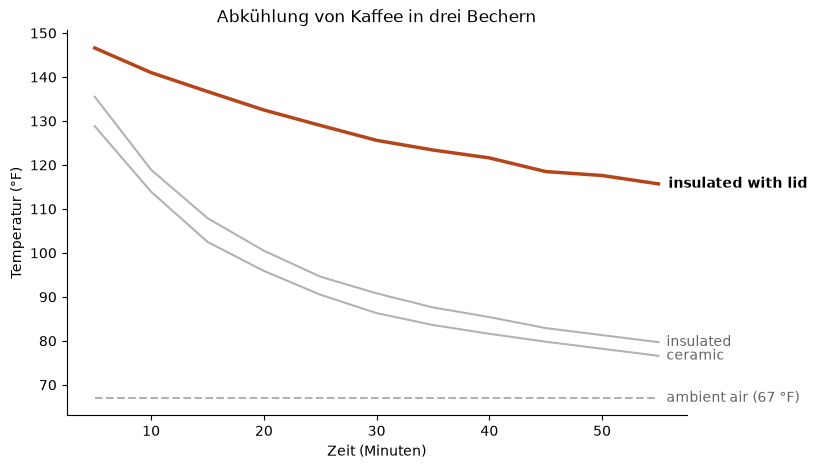

In [4]:
import doctest


def plot_coffee(data: pd.DataFrame, highlight: str = "insulated with lid", ambient: float = 67) -> plt.Axes:
    """Zeichnet die Temperatur in jedem Becher gegen die Zeit, hebt einen Becher hervor und zeigt die Raumtemperatur.

    >>> toy = pd.DataFrame({"time": [5, 10], "insulated with lid": [150.0, 140.0], "ceramic": [130.0, 110.0]})
    >>> ax = plot_coffee(toy)
    >>> len(ax.lines), ax.get_xlabel(), ax.get_ylabel()
    (3, 'Zeit (Minuten)', 'Temperatur (°F)')
    >>> [(text.get_text().strip(), text.get_fontweight()) for text in ax.texts]
    [('ambient air (67 °F)', 'normal'), ('ceramic', 'normal'), ('insulated with lid', 'bold')]
    >>> ax.lines[0].get_xydata().tolist(), ax.lines[0].get_linestyle()
    ([[5.0, 67.0], [10.0, 67.0]], '--')
    >>> ax.spines["top"].get_visible(), ax.spines["right"].get_visible()
    (False, False)
    >>> plt.close(ax.figure)
    """
    # Alle Spalten außer der Zeit sind Becher
    cups = [column for column in data.columns if column != "time"]
    others = [cup for cup in cups if cup != highlight]
    first_time = data["time"].iloc[0]
    last_time = data["time"].iloc[-1]

    fig, ax = plt.subplots(figsize=(8, 5))

    # Raumtemperatur als Vergleich, nur über den gemessenen Zeitraum, damit die Beschriftung frei steht
    ax.plot([first_time, last_time], [ambient, ambient], color="gray", linestyle="--", alpha=0.6)
    ax.text(last_time, ambient, f"  ambient air ({ambient:g} °F)", va="center", alpha=0.6)

    # Die anderen Becher gedämpft in Grau, der hervorgehobene zuletzt, damit er oben liegt
    for cup in others:
        ax.plot(data["time"], data[cup], color="gray", alpha=0.6)
    ax.plot(data["time"], data[highlight], color="#b5451b", linewidth=2.5)

    # Beschriftung direkt an der Linie statt Legende (add_end_labels zeichnet auf die aktuelle Achse)
    add_end_labels(data, last_time, others, alpha=0.6)
    add_end_labels(data, last_time, [highlight], fontweight="bold")

    # Unnötige Rahmen weglassen
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_xlabel("Zeit (Minuten)")
    ax.set_ylabel("Temperatur (°F)")
    ax.set_title("Abkühlung von Kaffee in drei Bechern")
    return ax


plot_coffee(df)
plt.show()

**Antwort:** Der Deckel macht's, damit ist der Kaffee nach knapp einer Stunde noch ~116 °F. Ohne Deckel bringt der Thermobecher fast nix, nur ~3 °F mehr als Keramik.

### Doctests

Die erwarteten Werte im Doctest sind an einer kleinen Beispieltabelle von Hand bestimmt, weil die Angabe keine Beispiele enthält.

In [5]:
doctest.testmod()

TestResults(failed=0, attempted=7)